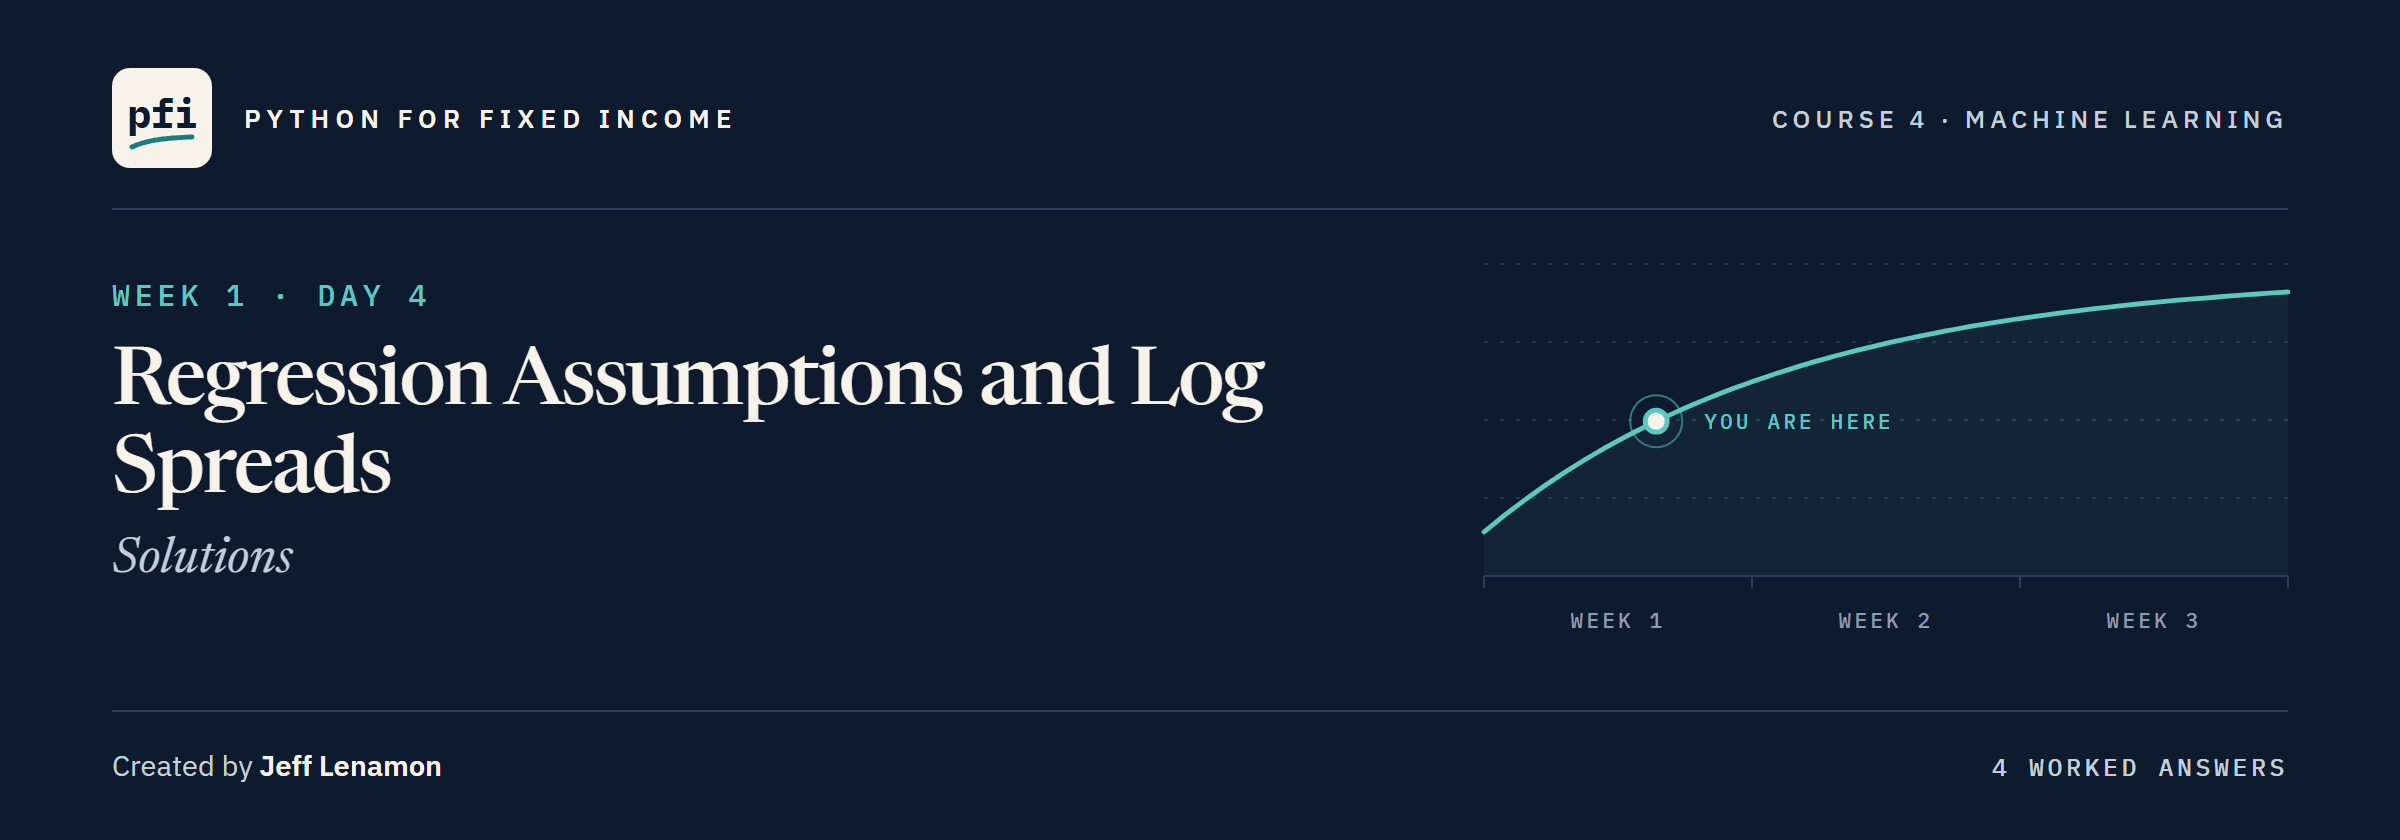

# Regression Assumptions and Log Spreads: Solutions

Week 1, Day 4. The full notebook with every exercise worked. Try each one yourself first.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course04_machine_learning/week1/day4/04_regression_assumptions_and_log_spreads_solutions.ipynb)

# Problem Statement

## Business Context

Day 3's kept model, 17 rating steps and years to maturity, misses a typical unseen bond by 35.4 bp.
statsmodels puts AAA's step at plus or minus 36.7 bp, while 500 refits on resampled bonds move it by only 5.6 bp.
Before anyone quotes a step, the desk wants every assumption under the model checked, and a fix for any that fails.
The bonds and issuers are invented for this course.

## Objectives

Check linearity, constant variance, normality and independence, each with a chart and a number.
Find why the bp model fails two of them, refit on the log of OAS, and check again.
Bring the log model back to bp, read a rating step as a percent, repair the error bars, and decide what to do with six distressed bonds.

## Data Dictionary

`benchmark.csv`, one row per bond:

1. `cusip`: the bond's identifier
2. `ticker`: the issuer's short code, shared by all of its bonds
3. `issuer`: the issuer's name
4. `rating`: credit rating, AAA to CCC
5. `oas`: option-adjusted spread, bp, **the target**
6. `maturity` and `as_of_date`: dates, from which years to maturity is built

The file's other columns are not used today.

`ratings.csv` adds `score` (1 for AAA up to 18 for CCC) and `grade` (Investment Grade or High Yield).

# Setting Up

## Course Setup

Run this cell and move on: it fixes the seed and finds the course data.

In [1]:
# today's setup: the thread settings, the seed, and where the course data lives
import os
from pathlib import Path

# one thread for the maths libraries, so every run prints the same last digits (this must run before numpy is imported)
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"

# the seed: one number for every random choice, so every run makes the same choices
SEED = 42

# the course data: the repo's data folder on your machine, GitHub in Colab
DATA = "../../../data/"
if not Path(DATA + "benchmark.csv").exists():
    DATA = "https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/data/"

## Importing the Libraries

In [2]:
# to load and work with the data
import numpy as np
import pandas as pd

# to draw charts, and the normal and lognormal curves from scipy
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# statsmodels: least squares with error bars, and the Breusch-Pagan test of the noise size
import statsmodels.api as sm
from statsmodels.stats.diagnostic import het_breuschpagan

# to split the bonds, refit, and score
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# one look for every chart, and plain numbers with three decimals in every table
sns.set_theme(style="whitegrid")
sns.set_palette("colorblind")
plt.rcParams["figure.figsize"] = (10, 5)
pd.set_option("display.float_format", "{:,.3f}".format)

# Loading the Data

## Reading the Bonds and Adding Years to Maturity

In [3]:
# the 821 bonds, and the table that turns each rating into a score and a grade
bonds = pd.read_csv(DATA + "benchmark.csv")
ratings = pd.read_csv(DATA + "ratings.csv")
data = bonds.merge(ratings[["rating", "score", "grade"]], on="rating")

# each bond's years to maturity, Day 3's line
data["years_to_maturity"] = (pd.to_datetime(data["maturity"]) - pd.to_datetime(data["as_of_date"])).dt.days / 365.25

# Exploratory Data Analysis

## Data Overview

### Checking the Target

Q. How wide a range of spreads does the model have to fit?

In [4]:
# the spread of every bond, in bp
data["oas"].describe()

count     821.000
mean      179.079
std       185.523
min        15.000
25%        79.000
50%       125.000
75%       210.000
max     2,074.000
Name: oas, dtype: float64

The mean, 179 bp, sits well above the median, 125 bp: a long tail of wide bonds runs out to 2,074 bp.

**The file is the one Days 1 to 3 checked. Today the question is the model's assumptions, not the data.**

## OAS in bp and in Logs

Q. On which scale do the spreads look more even?

`np.log`, from Course 1, takes the natural log of every spread.

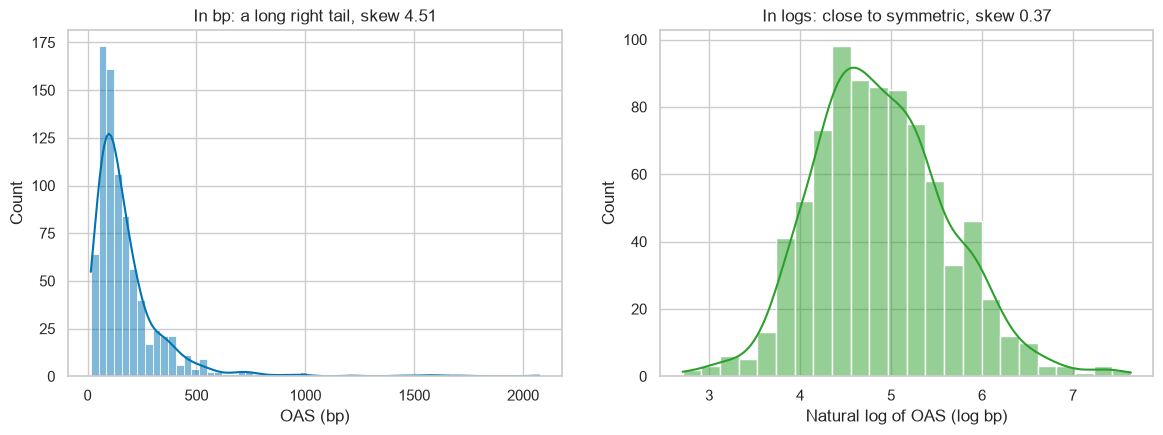

In [5]:
# OAS in bp and its natural log, side by side, each panel titled with its skew
log_oas = np.log(data["oas"])
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.histplot(data["oas"], kde=True, ax=axes[0])
sns.histplot(log_oas, kde=True, color="tab:green", ax=axes[1])
axes[0].set_xlabel("OAS (bp)")
axes[1].set_xlabel("Natural log of OAS (log bp)")
axes[0].set_title("In bp: a long right tail, skew " + str(round(data["oas"].skew(), 2)))
axes[1].set_title("In logs: close to symmetric, skew " + str(round(log_oas.skew(), 2)))
plt.show()

Skew 4.51 in bp and 0.37 in logs: the log pulls the long right tail in.

**Spreads are lopsided in bp and close to symmetric in logs. Hold that thought, because first we test the bp model as Day 3 left it.**

# Data Preparation for Modeling

## Day 3's Columns and Split

In [6]:
# one column per rating in scale order, A left out as the reference level (Day 2)
rating_order = ratings["rating"]
rating_category = pd.Categorical(data["rating"], categories=rating_order)
rating_dummies = pd.get_dummies(rating_category, prefix="rating", dtype=float).drop(columns="rating_A")

# Day 3's kept columns, the 17 rating steps and years to maturity, and the target: OAS in bp
X = pd.concat([rating_dummies, data["years_to_maturity"]], axis=1)
y = data["oas"]

# hold back a quarter of the bonds with the course seed
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=SEED)
print("Training bonds:", len(X_train), " Test bonds:", len(X_test))

Training bonds: 615  Test bonds: 206


**The same columns, bonds and split as Day 3's kept model.**

# Model Building

## Day 3's Model in `statsmodels`

In [7]:
# Day 3's kept model on the training bonds
bp_model = sm.OLS(y_train, sm.add_constant(X_train)).fit()
print("R-squared:", round(bp_model.rsquared, 4))

R-squared: 0.6746


## Fitted Values and Residuals

`.fittedvalues` holds the model's fitted spread for each training bond, and `.resid` its miss, actual less fitted.

Every check today reads these two columns.

In [8]:
# each training bond's fitted spread and its miss, in bp
bp_checks = pd.DataFrame({"fitted": bp_model.fittedvalues, "residual": bp_model.resid})
bp_checks.head()

,fitted,residual
712,50.746,-1.746
181,77.864,-18.864
778,28.038,-6.038
716,144.360,72.640
636,118.649,9.351


# Assumptions of Linear Regression

Day 3's error bars and p-values rest on four assumptions about the misses:

* **Linearity**: the misses average zero at every fitted spread.
* **Independence**: one bond's miss says nothing about another's.
* **Constant variance**: every bond's noise is the same size.
* **Normality**: the misses follow a bell curve.

## Test for Linearity

**Why the check?** A model of the wrong shape misses on one side across a whole stretch of fitted spreads, as Day 1's line did at both ends.

**How to check?** Plot the residuals against the fitted values with a **lowess** line, a smooth line drawn through the cloud piece by piece, each piece fitted on its nearby points.

`sns.residplot(lowess=True)` draws both.

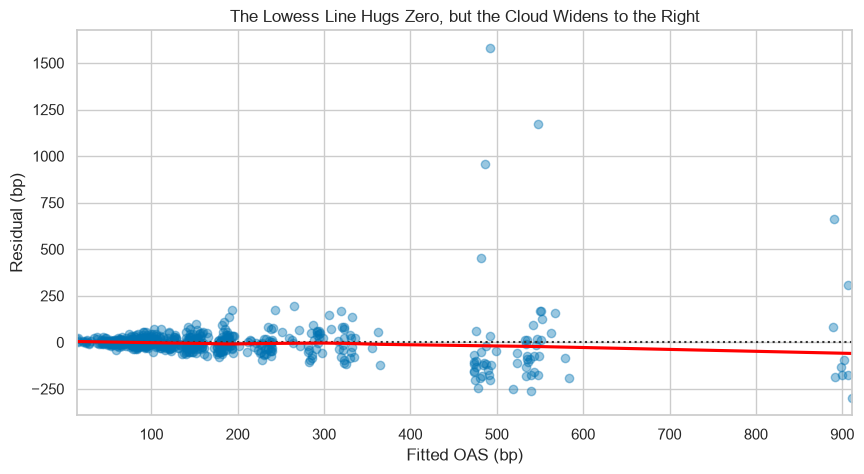

fitted
(14.39, 77.166]       1.606
(77.166, 101.923]     0.244
(101.923, 151.771]   -2.496
(151.771, 239.312]   -3.702
(239.312, 911.763]    4.348
Name: residual, dtype: float64

In [9]:
# the misses against the fitted spread, with a lowess line through them
plt.figure(figsize=(10, 5))
sns.residplot(data=bp_checks, x="fitted", y="residual", lowess=True,
              scatter_kws={"alpha": 0.4}, line_kws={"color": "red"})
plt.xlabel("Fitted OAS (bp)")
plt.ylabel("Residual (bp)")
plt.title("The Lowess Line Hugs Zero, but the Cloud Widens to the Right")
plt.show()

# the average miss in each fifth of the fitted spreads, in bp
bp_checks.groupby(pd.qcut(bp_checks["fitted"], 5))["residual"].mean()

Every fifth of the fitted spreads misses by less than 4.4 bp on average.
A step for every rating makes each rating's misses average zero, so Day 1's U is gone.

The cloud still widens to the right.

## Test for Constant Variance

**Why the check?** Day 3's error bars give every bond one noise size.

Equal noise is **constant variance** (homoscedasticity), and noise that grows is **heteroscedasticity**, the fan.

**How to check?** Split the bonds into thirds by fitted spread with `pd.qcut` (Course 1) and compare the spread of the misses in each.

In [10]:
# the misses' standard deviation in each third of the fitted spreads, in bp
def std_by_third(fitted, residual):
    thirds = pd.qcut(fitted, 3, labels=["bottom", "middle", "top"])
    return residual.groupby(thirds).std()

bp_thirds = std_by_third(bp_model.fittedvalues, bp_model.resid)
print(bp_thirds)
print("Top over bottom:", round(bp_thirds["top"] / bp_thirds["bottom"], 1))

bottom    15.866
middle    31.212
top      187.483
dtype: float64
Top over bottom: 11.8


The top third's misses are 11.8 times as wide as the bottom third's.

Setting the top of the range against the bottom is the idea behind the Goldfeld-Quandt test.

The size of each miss against the fitted spread shows it as one rising line, a **scale-location plot**.

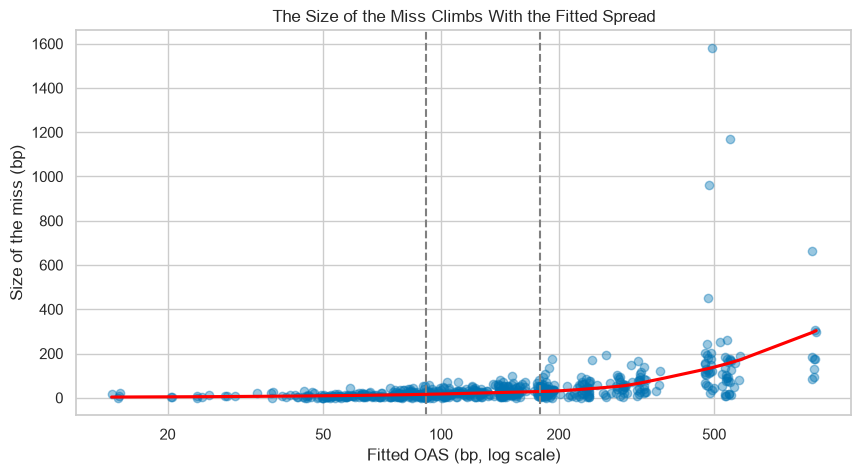

In [11]:
# the size of each miss against the fitted spread, a lowess line through them, the thirds' edges dashed
plt.figure(figsize=(10, 5))
sns.regplot(x=bp_checks["fitted"], y=bp_checks["residual"].abs(), lowess=True,
            scatter_kws={"alpha": 0.4}, line_kws={"color": "red"})
for edge in bp_checks["fitted"].quantile([1 / 3, 2 / 3]):
    plt.axvline(edge, color="gray", linestyle="--")
plt.xscale("log")
plt.xticks([20, 50, 100, 200, 500], [20, 50, 100, 200, 500])
plt.xlabel("Fitted OAS (bp, log scale)")
plt.ylabel("Size of the miss (bp)")
plt.title("The Size of the Miss Climbs With the Fitted Spread")
plt.show()

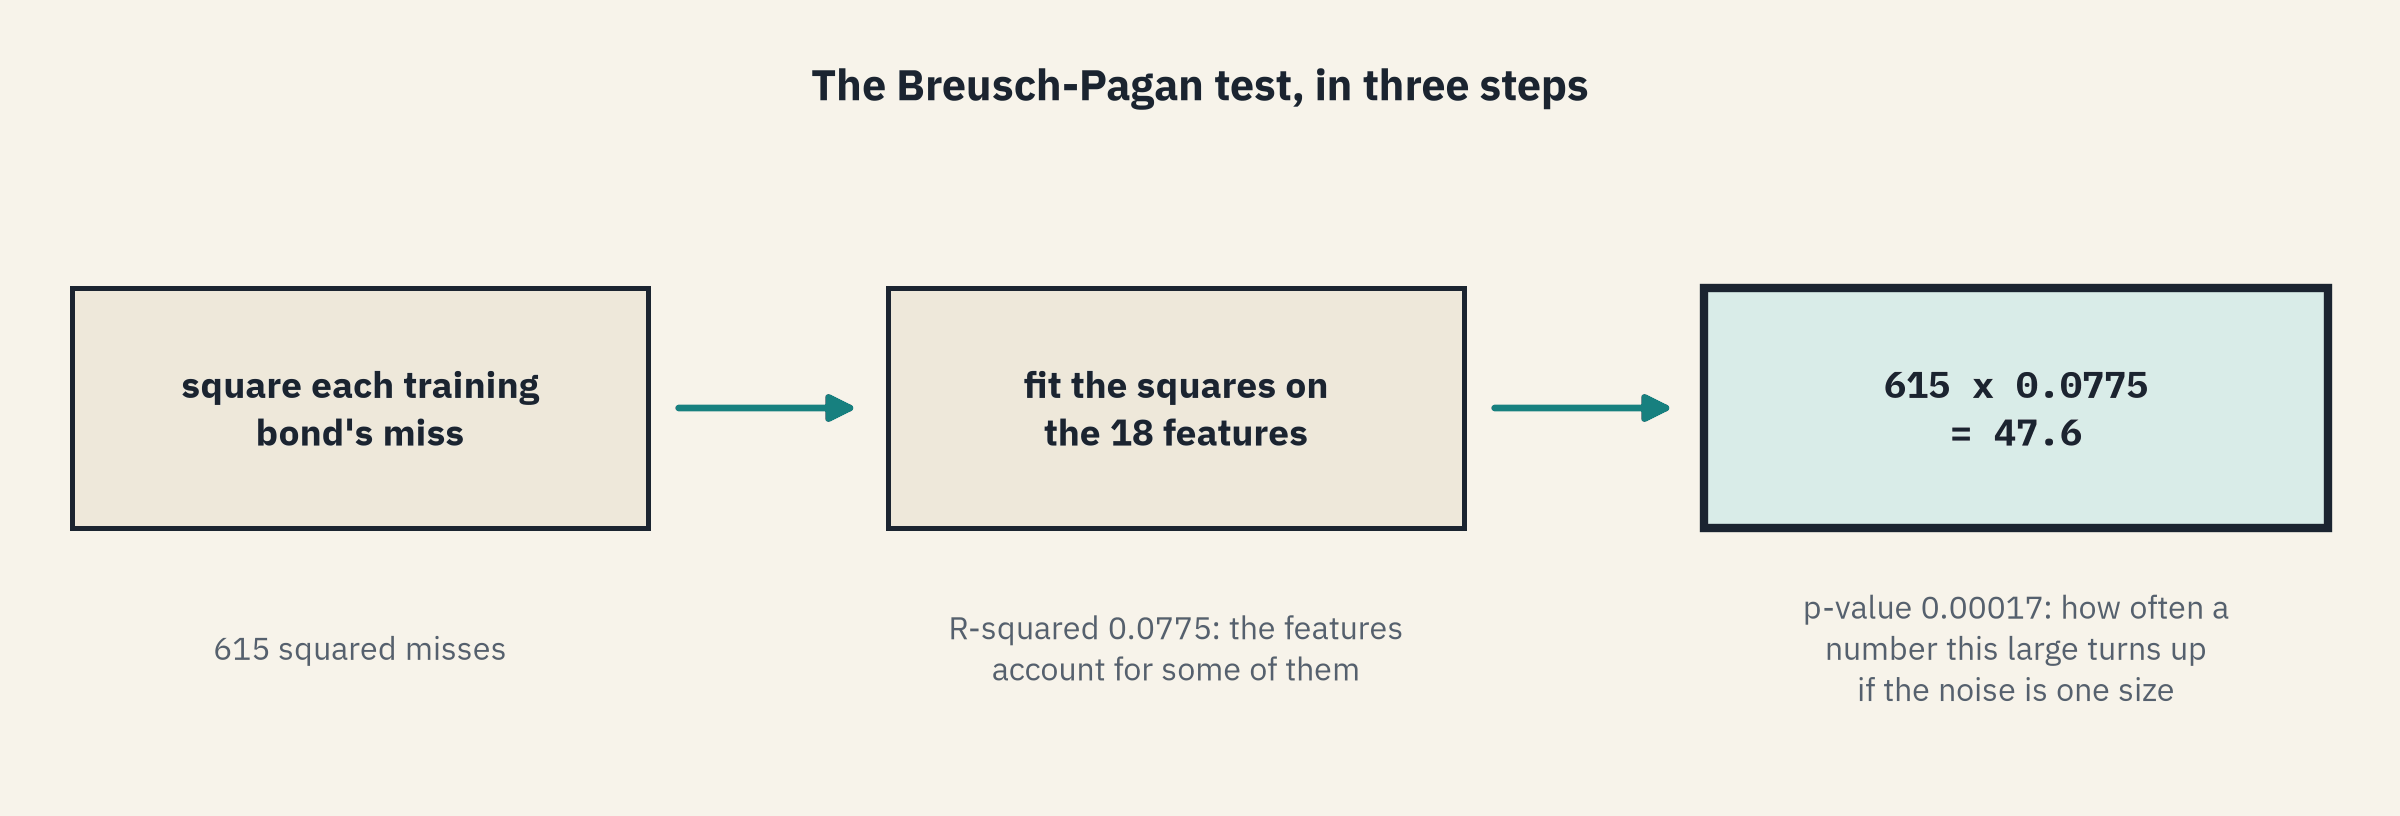

The **Breusch-Pagan test** asks the same question of all the features at once: do they account for the squared misses?

Its **null hypothesis**, the claim a test starts from, is that the noise is one size, and a small p-value rejects it.

`het_breuschpagan` takes the residuals and the model's columns, `.model.exog`, and returns four numbers.

In [12]:
# Breusch-Pagan: do the squared misses move with the features?
lm, lm_p_value, f, f_p_value = het_breuschpagan(bp_model.resid, bp_model.model.exog)
print("Breusch-Pagan statistic:", round(lm, 1), " p-value:", round(lm_p_value, 5))

Breusch-Pagan statistic: 47.6  p-value: 0.00017


A p-value of 0.00017 rejects one noise size: the fan is real.

## Test for Normality

**Why the check?** Day 3's p-values assume the misses follow a bell curve.

**How to check?** A histogram against a normal curve of the same standard deviation, then a Q-Q plot and two tests.

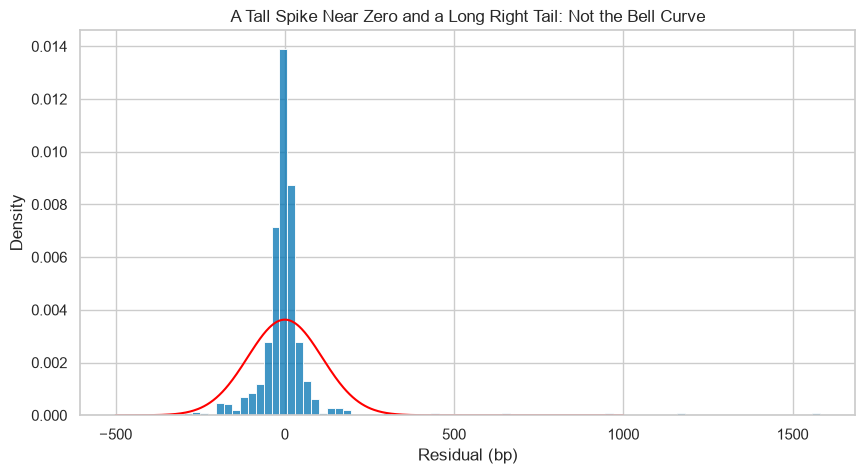

In [13]:
# the misses as a density, and the normal curve with the same standard deviation
grid = np.linspace(-500, 1000, 500)
plt.figure(figsize=(10, 5))
sns.histplot(bp_checks["residual"], stat="density", bins=80)
plt.plot(grid, stats.norm.pdf(grid, 0, bp_checks["residual"].std()), color="red")
plt.xlabel("Residual (bp)")
plt.title("A Tall Spike Near Zero and a Long Right Tail: Not the Bell Curve")
plt.show()

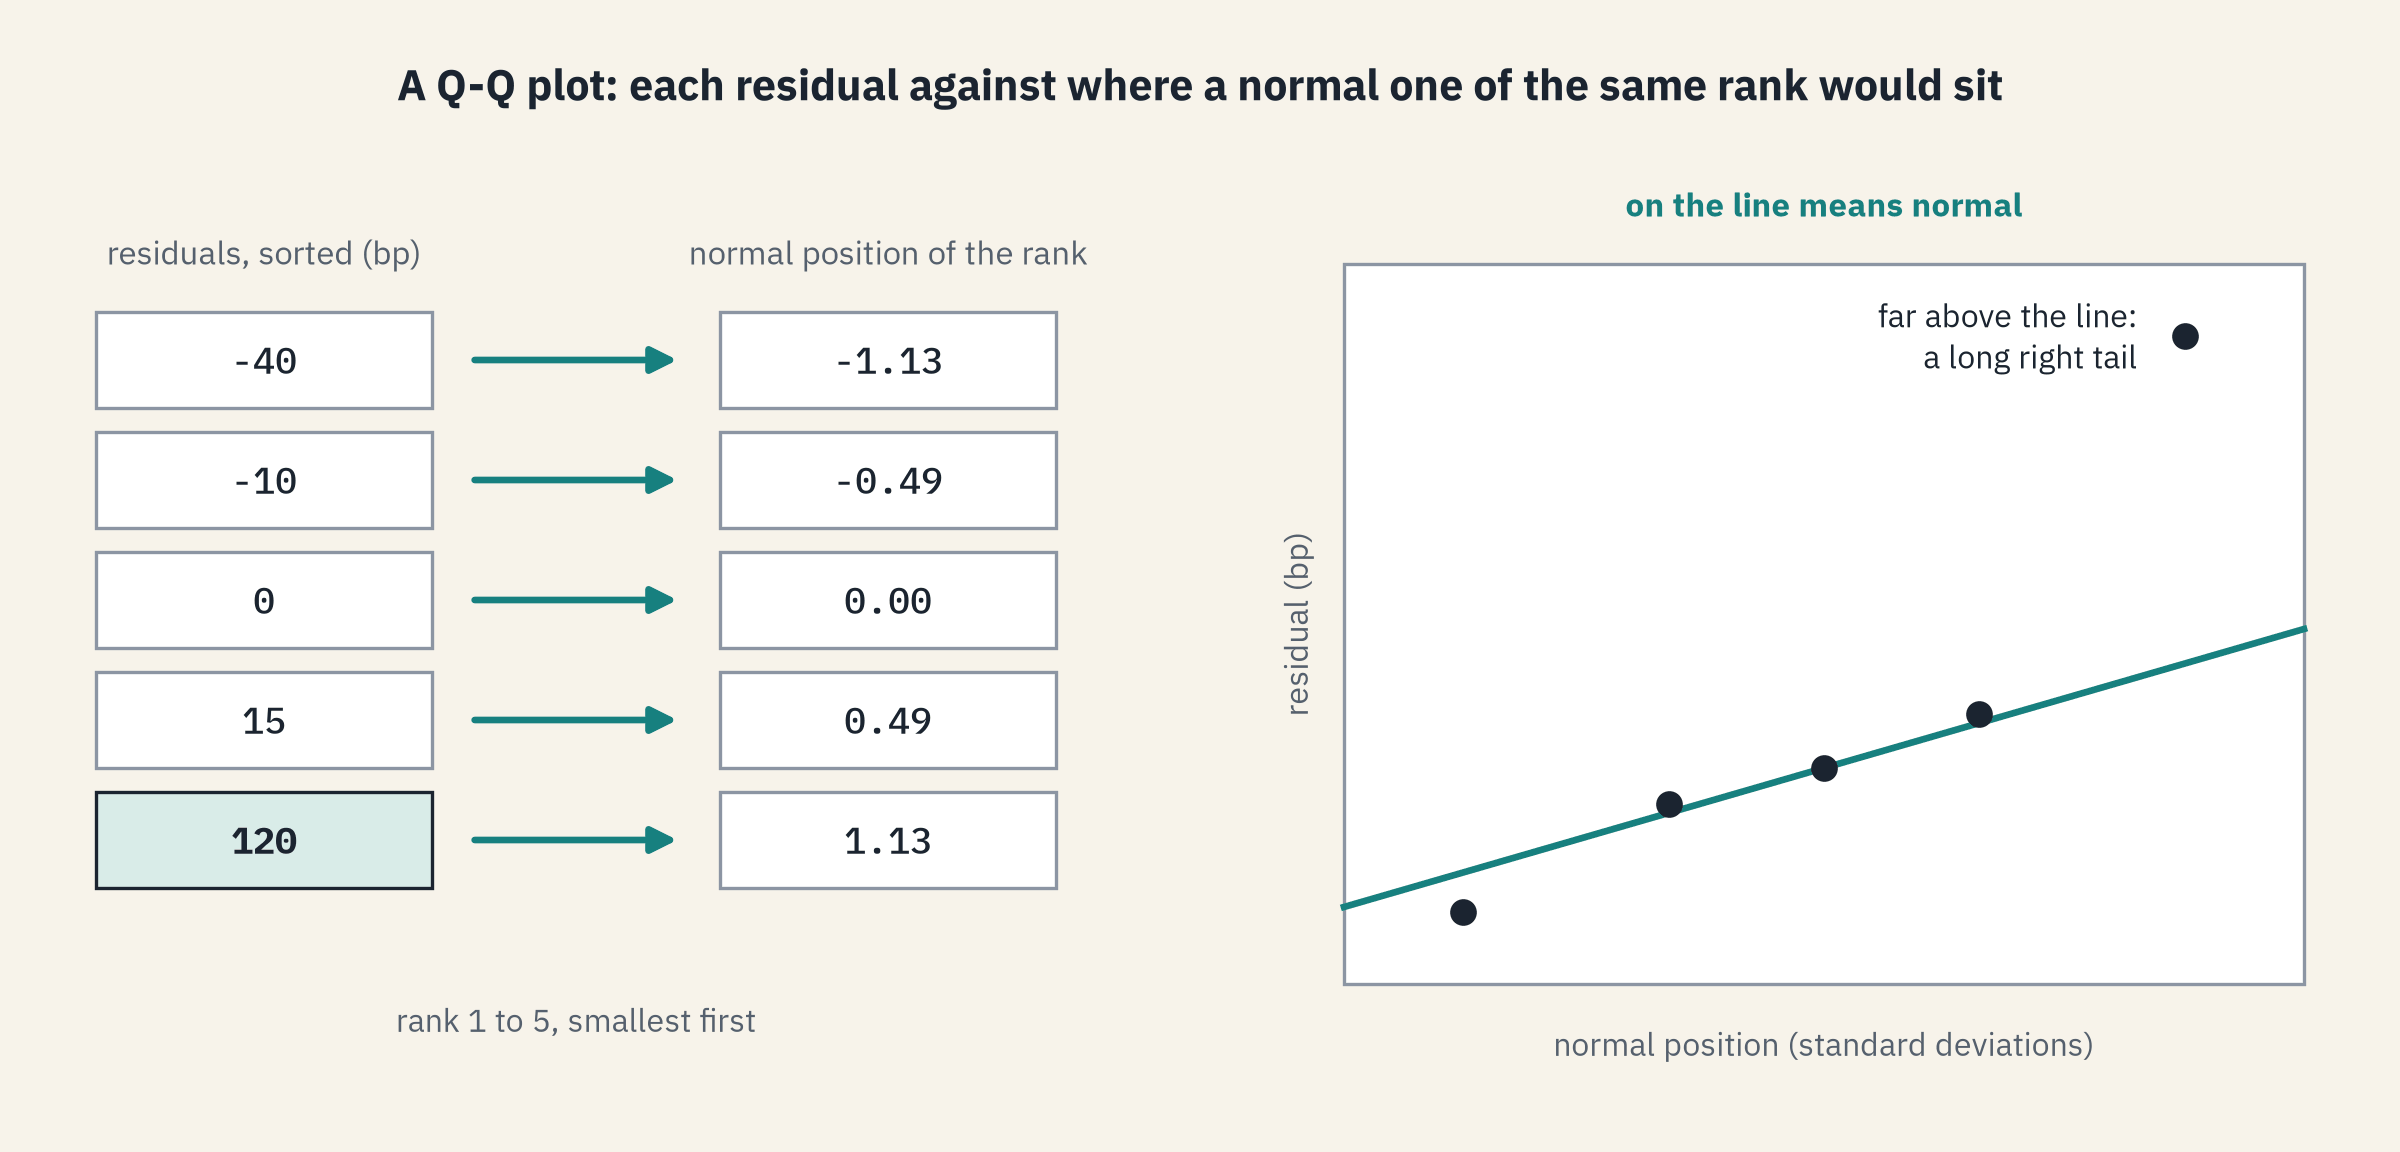

A **Q-Q plot** sorts the residuals and sets each against where a normal residual of the same rank would sit.

On the line means normal.

`stats.probplot(..., dist="norm", plot=ax)` draws it.

**Shapiro-Wilk** and **Jarque-Bera** test the same thing, each with the null hypothesis that the residuals are normal.

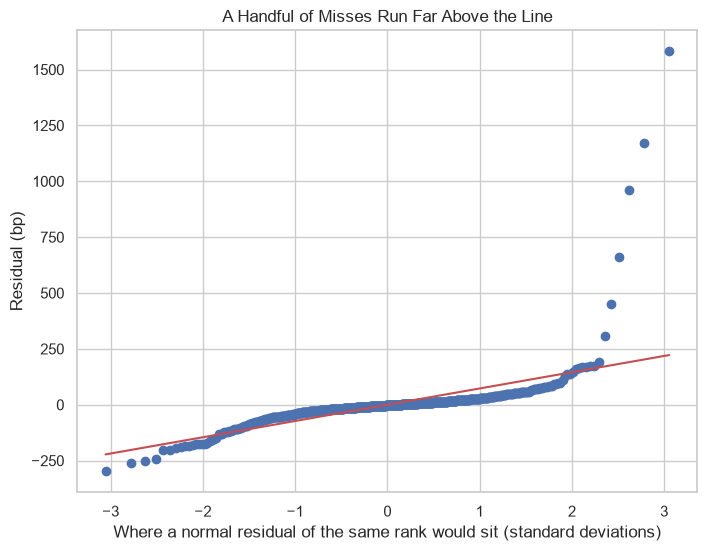

Skew: 8.2
Shapiro-Wilk p-value: 8.678412492899075e-40
Jarque-Bera p-value: 0.0


In [14]:
# a Q-Q plot: each residual against where a normal residual of the same rank would sit
fig, ax = plt.subplots(figsize=(8, 6))
stats.probplot(bp_checks["residual"], dist="norm", plot=ax)
ax.set_xlabel("Where a normal residual of the same rank would sit (standard deviations)")
ax.set_ylabel("Residual (bp)")
ax.set_title("A Handful of Misses Run Far Above the Line")
plt.show()

# two tests: a small p-value rejects "the residuals are normal"
print("Skew:", round(bp_checks["residual"].skew(), 1))
print("Shapiro-Wilk p-value:", stats.shapiro(bp_checks["residual"]).pvalue)
print("Jarque-Bera p-value:", stats.jarque_bera(bp_checks["residual"]).pvalue)

The middle of the Q-Q plot follows the line, and a handful of misses run far above it on the right.

Skew 8.2, and both p-values are as good as zero.

**Shape passes, while constant variance and normality fail badly. Next, why a bp model fans.**

# Why the bp Model Fans, and the Cure

## The Recipe Multiplies

Days 2 and 3 revealed parts of the course's recipe for spreads, and here is all of it.

![The course recipe for a spread: a base for the rating times a maturity factor times an issuer factor of about 15 percent either way times a bond factor of about 18 percent either way, and below it the same recipe in logs as a sum, where the issuer noise is one size for every issuer and the bond noise one size for every bond](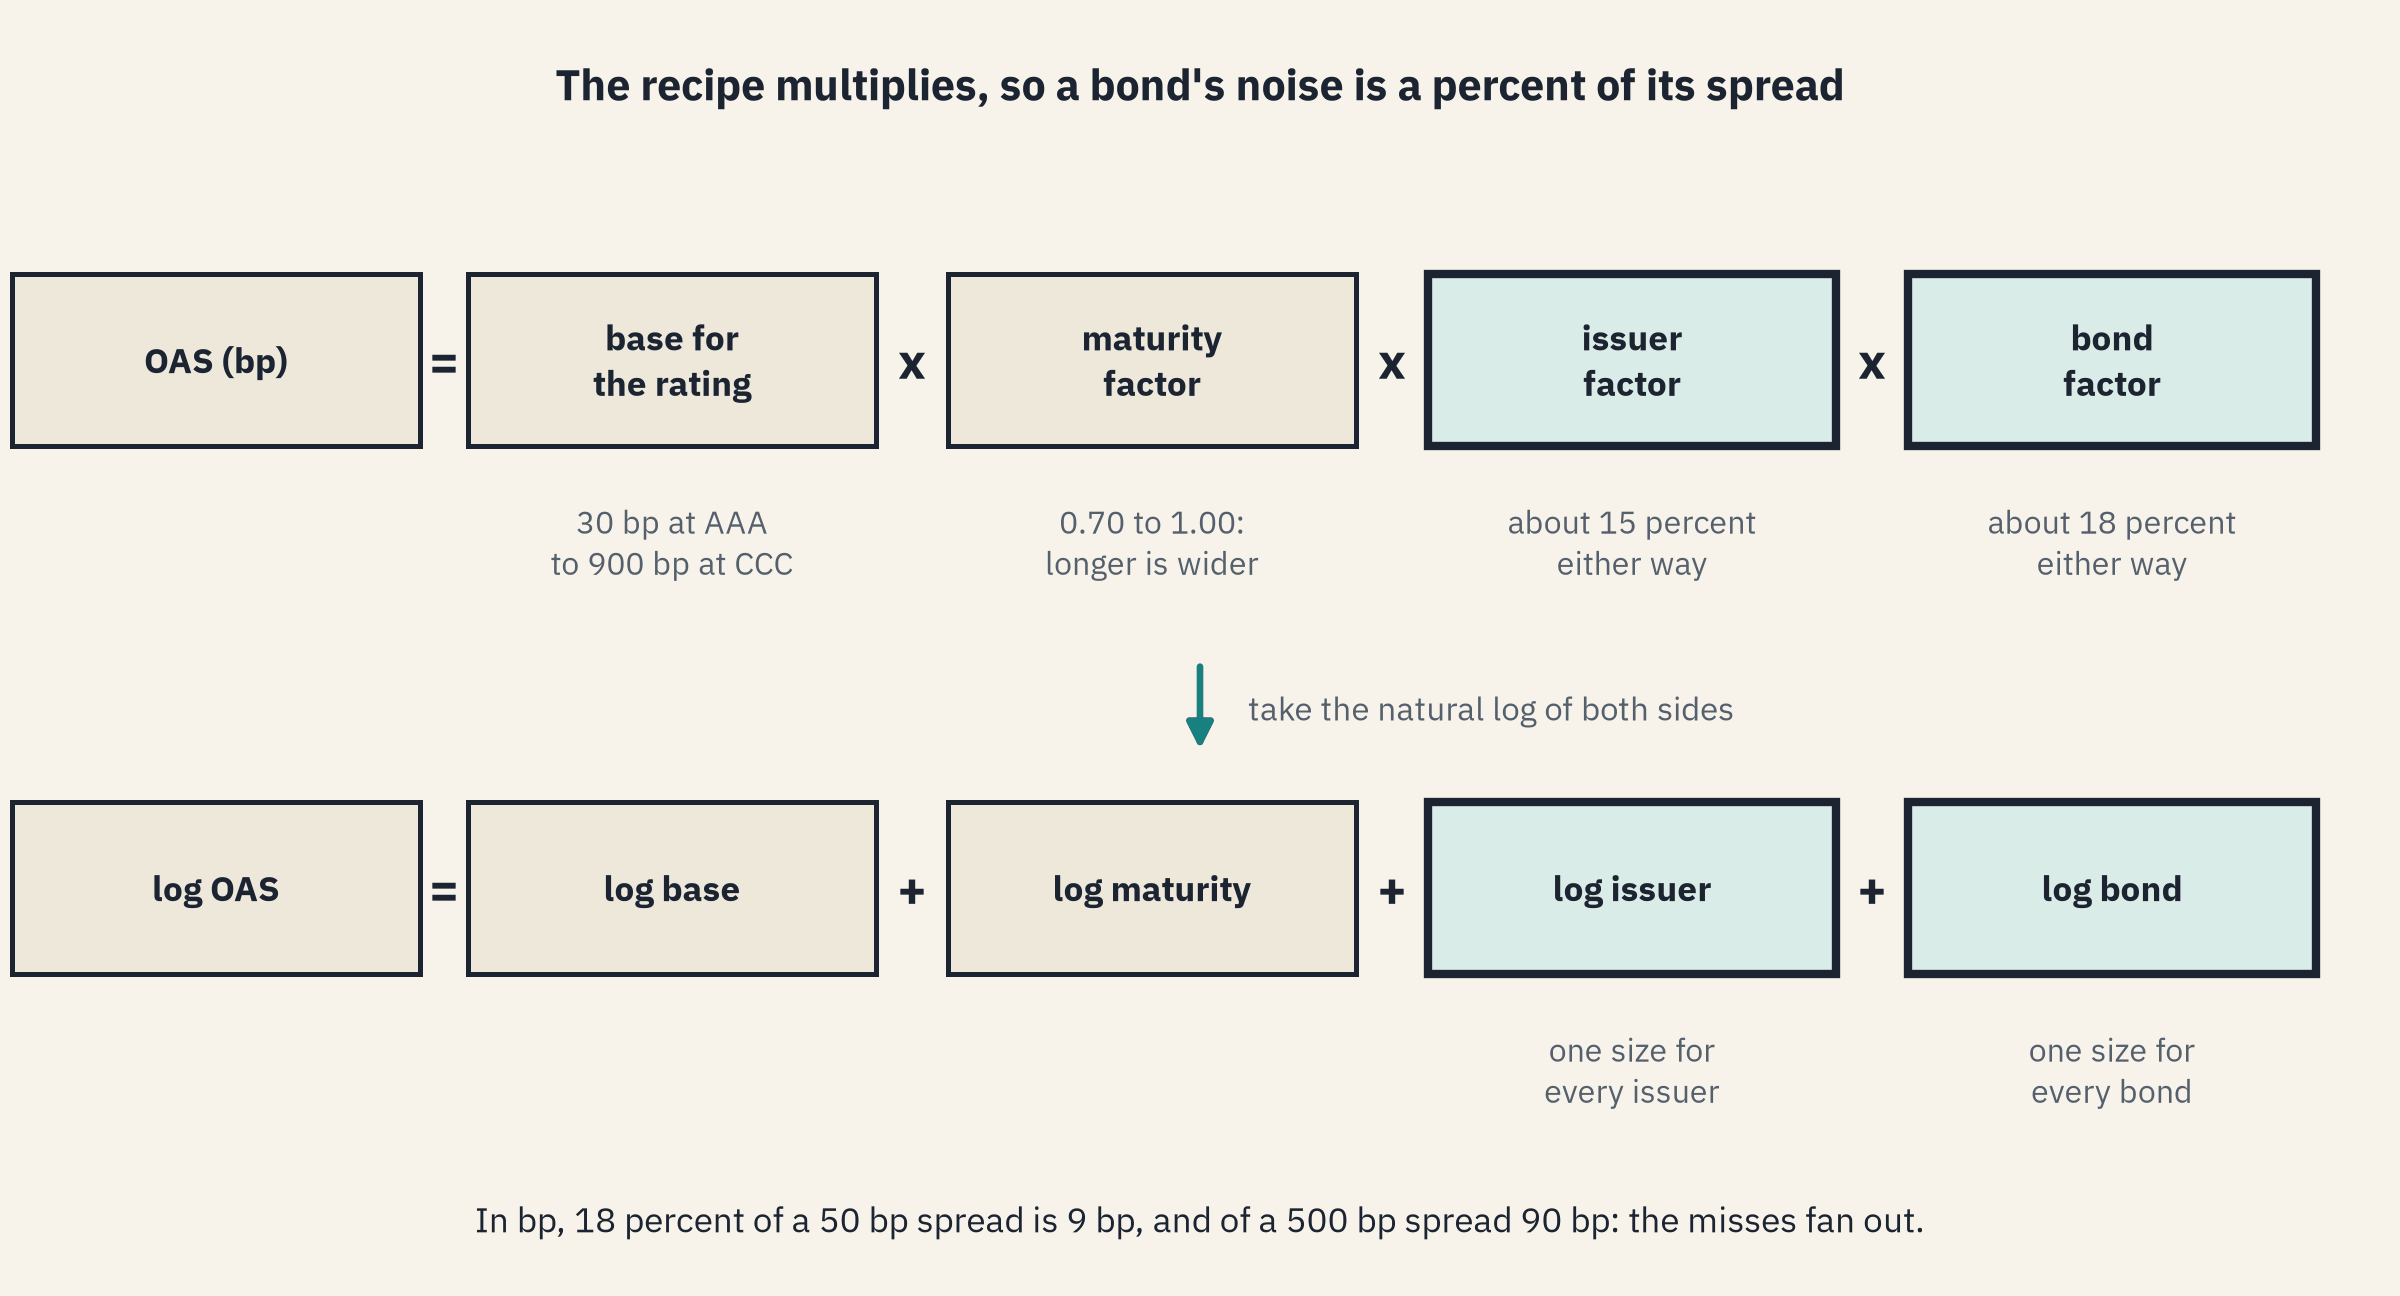)

A bond's spread is its rating's base times a maturity factor, times its issuer's factor, times a factor of its own.

The last two are the noise, and each is a percent: about 15 percent for an issuer and 18 percent for a bond.

So the misses in bp should grow in step with the spread.

## Noise Grows With the Spread

Q. Does each rating's noise grow in step with its spread?

In [15]:
# each rating's training bonds: the average fitted spread, the misses' standard deviation, and the count
by_rating = bp_checks.groupby(data.loc[X_train.index, "rating"]).agg(
    level=("fitted", "mean"), noise=("residual", "std"), bonds=("residual", "size")).loc[rating_order]
by_rating["noise_share"] = by_rating["noise"] / by_rating["level"]
by_rating.T

rating,AAA,AA+,AA,AA-,A+,A,A-,BBB+,BBB,BBB-,BB+,BB,BB-,B+,B,B-,CCC+,CCC
level,24.545,41.500,33.750,47.133,56.321,74.603,92.075,104.544,123.595,152.039,189.531,240.657,295.667,331.250,485.643,547.120,899.667,532.333
noise,16.320,15.519,6.561,15.667,12.022,16.764,23.351,22.457,32.843,37.310,44.712,64.002,65.402,83.341,391.072,270.994,305.864,102.553
bonds,11.000,4.000,4.000,15.000,56.000,58.000,80.000,57.000,42.000,77.000,64.000,35.000,27.000,20.000,28.000,25.000,9.000,3.000
noise_share,0.665,0.374,0.194,0.332,0.213,0.225,0.254,0.215,0.266,0.245,0.236,0.266,0.221,0.252,0.805,0.495,0.340,0.193


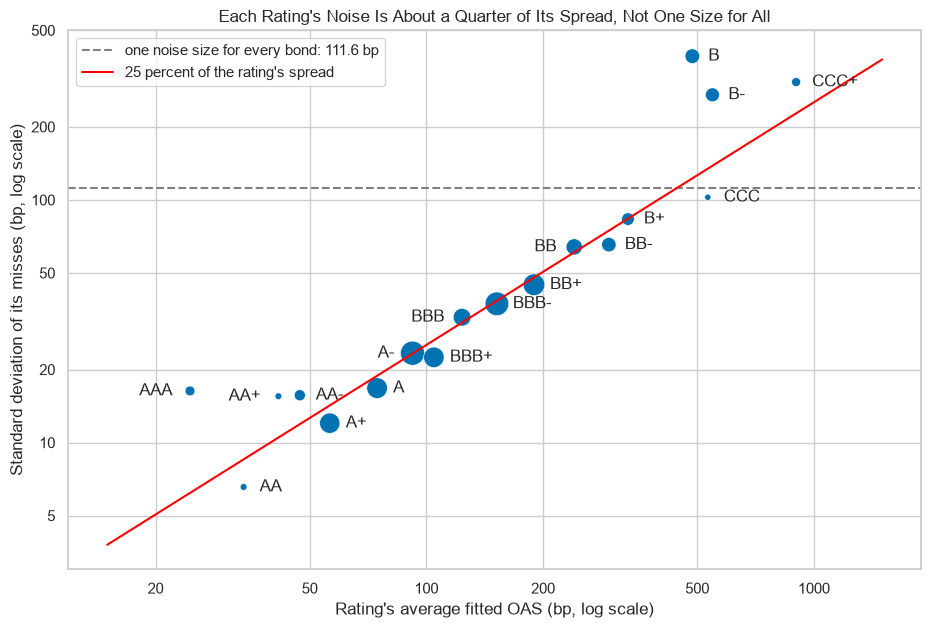

In [16]:
# the one noise size statsmodels assumes (Day 3), and the typical rating's noise as a share of its spread
one_size = np.sqrt(bp_model.scale)
typical_share = by_rating["noise_share"].median()

# one dot per rating, sized by its bonds; plt.text writes each label, left of the dot where a neighbour sits close
# (ha sets which end of the label touches the point, va="center" sets it level with the dot)
plt.figure(figsize=(11, 7))
sns.scatterplot(data=by_rating, x="level", y="noise", size="bonds", sizes=(20, 300), legend=False)
for rating, row in by_rating.iterrows():
    left = rating in ["AAA", "AA+", "A-", "BBB", "BB"]
    plt.text(row["level"] * (0.9 if left else 1.1), row["noise"], rating, ha="right" if left else "left", va="center")
plt.axhline(one_size, color="gray", linestyle="--", label="one noise size for every bond: " + str(round(one_size, 1)) + " bp")
plt.plot([15, 1500], [typical_share * 15, typical_share * 1500], color="red",
         label=str(round(typical_share * 100)) + " percent of the rating's spread")
plt.xscale("log")
plt.yscale("log")
plt.xticks([20, 50, 100, 200, 500, 1000], [20, 50, 100, 200, 500, 1000])
plt.yticks([5, 10, 20, 50, 100, 200, 500], [5, 10, 20, 50, 100, 200, 500])
plt.xlabel("Rating's average fitted OAS (bp, log scale)")
plt.ylabel("Standard deviation of its misses (bp, log scale)")
plt.title("Each Rating's Noise Is About a Quarter of Its Spread, Not One Size for All")
plt.legend()
plt.show()

From A+ to B+, ratings with 20 to 80 training bonds each, the noise is 21 to 27 percent of the spread.

The flat line, statsmodels' one noise size, is 111.6 bp: about seven times AAA's 16.3 bp and about a third of CCC+'s 305.9 bp.

B sits far above the diagonal, at 80.5 percent of its spread, and the distressed bonds near the end show why.

**The noise is a percent of the spread, so the cure is a target where a percent is a fixed distance: the log.**

## Choosing a Transformation

### Your Turn: Pick the Power

A **transformation** fits the model to a function of OAS instead of OAS itself.

On the ladder of powers, 1 is OAS, 0.5 its square root, and the log stands at 0.

In bp the top third's misses are 11.8 times as wide as the bottom third's.

**Predict 1**

Write down the top-over-bottom ratio you expect for log OAS.

In [17]:
# refit Day 3's columns on OAS to a power, with the log standing in at power 0
def refit_power(power):
    target = np.log(y_train) if power == 0 else y_train ** power
    return sm.OLS(target, sm.add_constant(X_train)).fit()

In [18]:
# draw one power's misses against its fitted values; the title gives the top third over the bottom third
def draw_power(power=0.5):
    model = refit_power(power)
    thirds = std_by_third(model.fittedvalues, model.resid)
    plt.scatter(model.fittedvalues, model.resid, alpha=0.4)
    plt.axhline(0, color="red")
    plt.xlabel("Fitted value, OAS to the power " + str(power))
    plt.ylabel("Residual")
    plt.title("Power " + str(power) + ": the top third's misses are "
              + str(round(thirds["top"] / thirds["bottom"], 2)) + " times the bottom third's")
    plt.show()

In [19]:
# drag the slider from -0.5 to 1 in steps of 0.25
from ipywidgets import interact
interact(draw_power, power=(-0.5, 1.0, 0.25));

interactive(children=(FloatSlider(value=0.5, description='power', max=1.0, min=-0.5, step=0.25), Output()), _d…

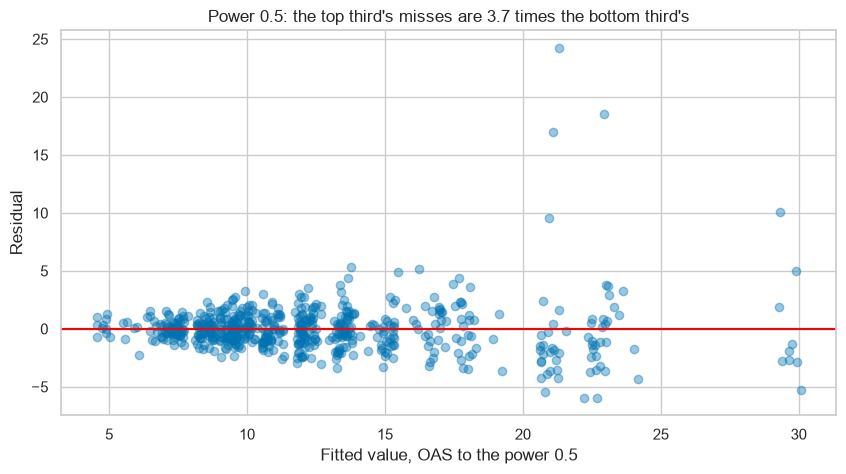

In [20]:
# the slider's starting position, drawn as a still picture (sliders do not run on GitHub)
draw_power(power=0.5)

In [21]:
# top over bottom at every stop on the slider
for power in [1, 0.5, 0.25, 0, -0.25, -0.5]:
    model = refit_power(power)
    thirds = std_by_third(model.fittedvalues, model.resid)
    print("Power", power, " top over bottom:", round(thirds["top"] / thirds["bottom"], 2))

Power 1  top over bottom: 11.82
Power 0.5  top over bottom: 3.7
Power 0.25  top over bottom: 2.18
Power 0  top over bottom: 1.32
Power -0.25  top over bottom: 1.23
Power -0.5  top over bottom: 1.93


The ratio falls from 11.82 at power 1 to 1.32 at the log, then climbs again past -0.25.

Power -0.25 edges the log on this one number, but only the log matches the recipe, and only the log reads as a percent.

**We refit on log OAS.**

# The Log Model, Fitted and Scored

## Model Building in Logs

In [22]:
# the same columns and bonds, with the log of OAS as the target
log_model = sm.OLS(np.log(y_train), sm.add_constant(X_train)).fit()
print("R-squared, in logs:", round(log_model.rsquared, 4))

R-squared, in logs: 0.8907


R-squared 0.8907 is measured in logs, so it cannot be set beside the bp model's 0.6746.

The test bonds, in bp, decide.

## Model Performance Evaluation

### Back to bp With `exp`

`np.exp` (Course 2) undoes the log, so `np.exp` of a fitted log is a fitted spread in bp.

The bp model misses unseen bonds by 35.4 bp.

**Predict 2**

Write down the log model's test MAE, in bp.

In [23]:
# each model's fitted spreads for the test bonds in bp: the log model's through exp
fitted_bp = bp_model.predict(sm.add_constant(X_test))
fitted_log_bp = np.exp(log_model.predict(sm.add_constant(X_test)))

# MAE, RMSE and R-squared on the test bonds, one row per model
test_scores = pd.DataFrame({
    "MAE (bp)": [mean_absolute_error(y_test, fitted_bp), mean_absolute_error(y_test, fitted_log_bp)],
    "RMSE (bp)": [np.sqrt(mean_squared_error(y_test, fitted_bp)), np.sqrt(mean_squared_error(y_test, fitted_log_bp))],
    "R-squared": [r2_score(y_test, fitted_bp), r2_score(y_test, fitted_log_bp)]}, index=["bp model", "log model"])
test_scores

,MAE (bp),RMSE (bp),R-squared
bp model,35.445,68.812,0.820
log model,33.109,69.500,0.816


In [24]:
# each test bond's miss in bp under both models, then the typical miss within each grade
test_misses = pd.DataFrame({"bp model": (y_test - fitted_bp).abs(), "log model": (y_test - fitted_log_bp).abs()})
test_misses.groupby(data.loc[X_test.index, "grade"]).mean()

,bp model,log model
grade,,
High Yield,63.406,56.505
Investment Grade,21.052,21.067


In [25]:
# Day 1's largest miss, Praxiskan Finance 99038MAC3, under both models
test_misses[data.loc[X_test.index, "cusip"] == "99038MAC3"]

,bp model,log model
196,714.790,785.771


The log model misses a typical test bond by 33.1 bp, 2.3 bp less than the bp model.

The gain is in high yield, from 63.4 to 56.5 bp, while investment grade stays at 21.1.

RMSE is a hair worse, 69.50 against 68.81, because the log model misses Praxiskan Finance by 785.8 bp against 714.8.

### What `exp` Gives Back

**Predict 3**

Of the 206 test bonds, how many sit above the spread `np.exp` gives back for them?

In [26]:
# how many test bonds sit above the spread exp gives back
print((y_test > fitted_log_bp).sum(), "of", len(y_test), "test bonds sit above their exp(fitted) spread")

108 of 206 test bonds sit above their exp(fitted) spread


108 of 206, close to half: `exp` of a fitted log is the middle bond for those features, not the average.

A **lognormal** curve shows why: when log spreads are normal around log(100), the middle bond is 100 bp and the long right tail pulls the average above it.

`stats.lognorm.pdf(grid, sigma, scale=100)` draws it, with sigma the log model's noise size, `np.sqrt(log_model.scale)`.

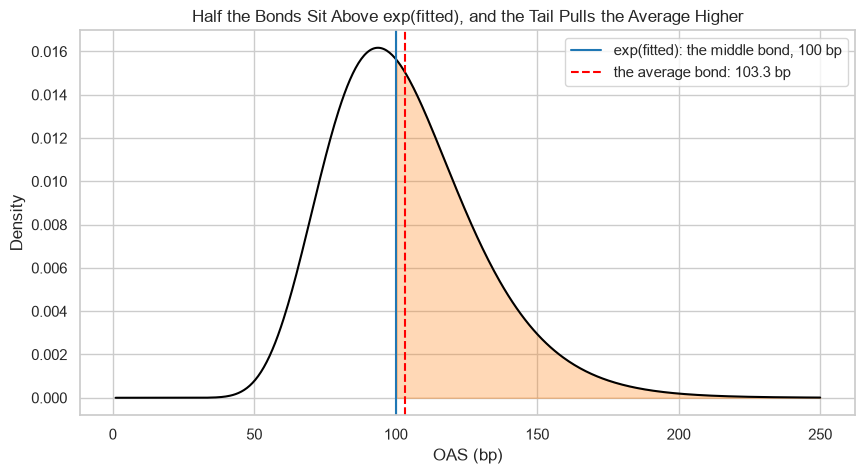

In [27]:
# bonds whose log spread is normal around log(100 bp), with the log model's noise size
sigma = np.sqrt(log_model.scale)
grid = np.linspace(1, 250, 500)
curve = stats.lognorm.pdf(grid, sigma, scale=100)
# stats.lognorm.mean gives the curve's average bond
average = stats.lognorm.mean(sigma, scale=100)
plt.figure(figsize=(10, 5))
plt.plot(grid, curve, color="black")
plt.fill_between(grid, curve, where=grid >= 100, color="tab:orange", alpha=0.3)
plt.axvline(100, color="tab:blue", label="exp(fitted): the middle bond, 100 bp")
plt.axvline(average, color="red", linestyle="--", label="the average bond: " + str(round(average, 1)) + " bp")
plt.xlabel("OAS (bp)")
plt.ylabel("Density")
plt.title("Half the Bonds Sit Above exp(fitted), and the Tail Pulls the Average Higher")
plt.legend()
plt.show()

In [28]:
# the average fitted spread against the average actual spread of the test bonds, in bp
print("Average exp(fitted):", round(fitted_log_bp.mean(), 1), " average OAS:", round(y_test.mean(), 1))

# every fitted spread scaled up by the training bonds' average exp(residual)
scale_up = np.exp(log_model.resid).mean()
print("Scale-up:", round(scale_up, 3), " test MAE after it:", round(mean_absolute_error(y_test, fitted_log_bp * scale_up), 2))

Average exp(fitted): 166.7  average OAS: 174.3
Scale-up: 1.035  test MAE after it: 33.63


The test bonds average 174.3 bp, and their `exp(fitted)` spreads 166.7 bp.

Scaling every fitted spread up by 1.035 brings the average closer and worsens the typical miss to 33.63 bp, so we keep the middle bond.

**In bp the log model misses a little less, all of it in high yield. Its real gain is in the checks.**

# Rechecking the Assumptions in Logs

## The Same Checks, Before and After

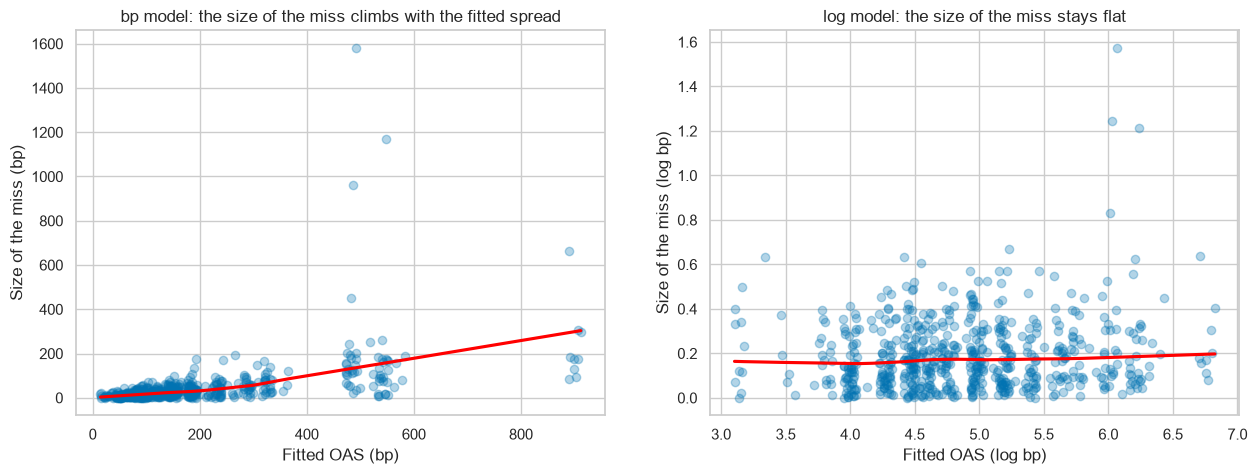

In [29]:
# the log model's fitted values and misses, in logs
log_checks = pd.DataFrame({"fitted": log_model.fittedvalues, "residual": log_model.resid})

# the size of each miss against the fitted value, bp model on the left, log model on the right
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, checks, unit in zip(axes, [bp_checks, log_checks], ["bp", "log bp"]):
    sns.regplot(x=checks["fitted"], y=checks["residual"].abs(), lowess=True, ax=ax,
                scatter_kws={"alpha": 0.3}, line_kws={"color": "red"})
    ax.set_xlabel("Fitted OAS (" + unit + ")")
    ax.set_ylabel("Size of the miss (" + unit + ")")
axes[0].set_title("bp model: the size of the miss climbs with the fitted spread")
axes[1].set_title("log model: the size of the miss stays flat")
plt.show()

In [30]:
# the four numbers again, for the log model
log_thirds = std_by_third(log_model.fittedvalues, log_model.resid)
print("Top over bottom:", round(log_thirds["top"] / log_thirds["bottom"], 2))
print("Breusch-Pagan p-value:", het_breuschpagan(log_model.resid, log_model.model.exog)[1])
print("Shapiro-Wilk p-value:", stats.shapiro(log_model.resid).pvalue)
print("Jarque-Bera p-value:", stats.jarque_bera(log_model.resid).pvalue)

Top over bottom: 1.32
Breusch-Pagan p-value: 0.0004110289449269253
Shapiro-Wilk p-value: 3.228611440549125e-11
Jarque-Bera p-value: 2.58316088875301e-88


Top over bottom falls from 11.8 to 1.32: the fan has closed.

The three tests still reject, and the distressed bonds near the end are the handful behind that.

## Test for Independence

**Why the check?** On Day 3, bonds of one issuer missed together in bp.

**How to check?** Day 3's measure: swap each miss for its issuer's average miss (`.transform("mean")`) and see what share of the squared misses survives, then shuffle the issuer labels and do it again.

In [31]:
# the share of the log misses that issuer averages account for, with real and with shuffled issuer labels
issuer = data.loc[X_train.index, "ticker"]
shuffled = np.random.default_rng(SEED).permutation(issuer.to_numpy())
for name, labels in [("real issuers", issuer), ("shuffled", shuffled)]:
    average = log_model.resid.groupby(labels).transform("mean")
    print(name, round((average ** 2).sum() / (log_model.resid ** 2).sum() * 100, 1), "percent")

real issuers 42.8 percent
shuffled 26.0 percent


42.8 percent with real issuers against 26.0 percent shuffled.

Logs fix the size of the noise, not the issuer effect, so bonds of one issuer still miss together.

Error bars clustered by issuer are a later topic.

**The noise is one size in logs, apart from a handful of bonds. Now read the coefficients.**

# Coefficients and Error Bars in Logs

## Reading a Coefficient in Logs

### A Step as a Percent

A difference in logs is a ratio.

So a coefficient b on log OAS means a spread exp(b) times as large: 100 x (exp(b) - 1) percent different.

In [32]:
# every coefficient as a percent: 100 x (exp(coefficient) - 1), and its 95 percent interval the same way
# .conf_int() holds each interval's low end in column 0 and its high end in column 1
percent = 100 * (np.exp(log_model.params) - 1)
percent_interval = 100 * (np.exp(log_model.conf_int()) - 1)
percent_interval.assign(percent=percent).loc[["rating_AAA", "rating_BB", "years_to_maturity"]]

,0,1,percent
rating_AAA,-72.489,-61.766,-67.568
rating_BB,178.526,245.298,210.120
years_to_maturity,0.662,1.275,0.968


Holding years fixed, a BB bond's spread sits 210.1 percent above an A bond's, with an interval of 178.5 to 245.3.

AAA sits 67.6 percent below A, and a year to maturity goes with 0.97 percent more spread.

"Goes with", never "causes".

### The Steps Against the Recipe

In [33]:
# the recipe's typical spread for a 10-year bond of each rating, in bp, from the course's generator
recipe = pd.Series([30, 40, 48, 56, 68, 80, 95, 115, 135, 165, 215, 260, 310, 370, 440, 530, 720, 900], index=rating_order)

# each rating's multiplier from A, exp(coefficient), with its 95 percent band (A is 1 by definition), and the recipe's
names = "rating_" + rating_order
band = np.exp(log_model.conf_int().reindex(names).fillna(0))
multipliers = pd.DataFrame({"fitted": np.exp(log_model.params.reindex(names).fillna(0)).to_numpy(),
                            "low": band[0].to_numpy(), "high": band[1].to_numpy(),
                            "recipe": (recipe / recipe["A"]).to_numpy()}, index=rating_order)
multipliers.T

rating,AAA,AA+,AA,AA-,A+,A,A-,BBB+,BBB,BBB-,BB+,BB,BB-,B+,B,B-,CCC+,CCC
fitted,0.324,0.507,0.459,0.627,0.756,1.000,1.205,1.355,1.617,2.015,2.498,3.101,3.867,4.337,5.666,6.892,11.845,7.058
low,0.275,0.390,0.355,0.542,0.688,1.000,1.105,1.233,1.461,1.847,2.281,2.785,3.441,3.808,5.049,6.114,9.901,5.248
high,0.382,0.658,0.595,0.724,0.830,1.000,1.313,1.489,1.790,2.198,2.736,3.453,4.347,4.938,6.357,7.770,14.171,9.493
recipe,0.375,0.500,0.600,0.700,0.850,1.000,1.188,1.438,1.688,2.062,2.688,3.250,3.875,4.625,5.500,6.625,9.000,11.250


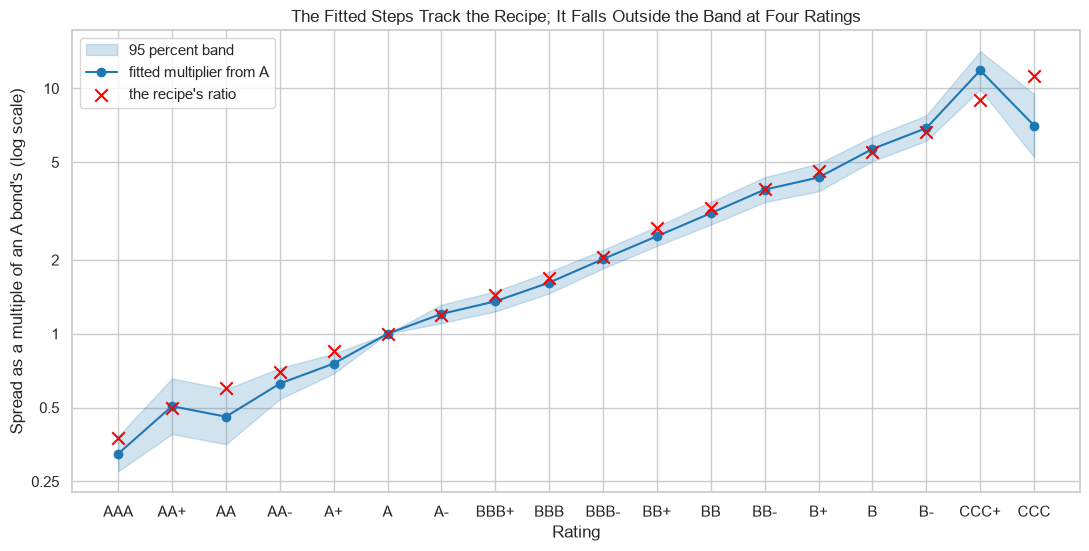

In [34]:
# the fitted multipliers with their band, and the recipe's own ratios as crosses, on a log axis
position = np.arange(len(rating_order))
plt.figure(figsize=(13, 6))
plt.fill_between(position, multipliers["low"], multipliers["high"], color="tab:blue", alpha=0.2, label="95 percent band")
plt.plot(position, multipliers["fitted"], marker="o", color="tab:blue", label="fitted multiplier from A")
plt.scatter(position, multipliers["recipe"], marker="x", s=80, color="red", zorder=3, label="the recipe's ratio")
plt.yscale("log")
plt.yticks([0.25, 0.5, 1, 2, 5, 10], [0.25, 0.5, 1, 2, 5, 10])
plt.xticks(position, rating_order)
plt.xlabel("Rating")
plt.ylabel("Spread as a multiple of an A bond's (log scale)")
plt.title("The Fitted Steps Track the Recipe; It Falls Outside the Band at Four Ratings")
plt.legend()
plt.show()

A BB bond's spread is fitted at 3.10 times an A bond's against the recipe's 3.25, BB- at 3.87 against 3.88, AAA at 0.32 against 0.375.

The band is widest at AA+, AA and CCC, with three or four training bonds each.

The recipe falls just outside the band at A+ and AA, and far outside at CCC+ and CCC.

The band treats every bond as independent, while bonds of one issuer miss together, so it comes out narrower than it should.

## When the Error Bars Are Right

### Refits in Logs

Day 3's 500 refits on resampled bonds, with the target as the input, run once for each target.

In [35]:
# draw 615 training bonds with replacement, refit, keep the coefficients; 500 times (Day 3's loop, any target)
def resampled_coefficients(target):
    rng = np.random.default_rng(SEED)
    rows = []
    for i in range(500):
        picks = rng.choice(len(X_train), size=len(X_train))
        refit = LinearRegression().fit(X_train.iloc[picks], target.iloc[picks])
        rows.append(refit.coef_)
    return pd.DataFrame(rows, columns=X_train.columns)

bp_refits = resampled_coefficients(y_train)
log_refits = resampled_coefficients(np.log(y_train))

### Robust Standard Errors

**HC3** standard errors, from `fit(cov_type="HC3")`, let each bond's noise be its own size, read from that bond's own miss.

The chart sets each rating step's reported standard error against the spread of its 500 refits, on log axes.

On the 45-degree line, drawn by `ax.axline`, the two agree.

AA+, AA and CCC stay out: with three or four training bonds each, some refits draw none of them and cannot fit their step.

**Predict 4**

Sketch the third panel, the log model's usual standard errors: where do its 14 dots sit?

In [36]:
# the bp model again, with HC3 standard errors
hc3_model = sm.OLS(y_train, sm.add_constant(X_train)).fit(cov_type="HC3")

# the rating steps with at least 9 training bonds, and each step's grade
bonds_per_step = X_train[rating_dummies.columns].sum()
step_names = bonds_per_step[bonds_per_step >= 9].index
step_grade = ratings.set_index("rating")["grade"][step_names.str.replace("rating_", "")].to_numpy()

# three panels, each a model's reported standard errors and the refits they are checked against
panels = [("bp, usual (bp)", bp_model.bse, bp_refits), ("bp, HC3 (bp)", hc3_model.bse, bp_refits),
          ("logs, usual (log bp)", log_model.bse, log_refits)]

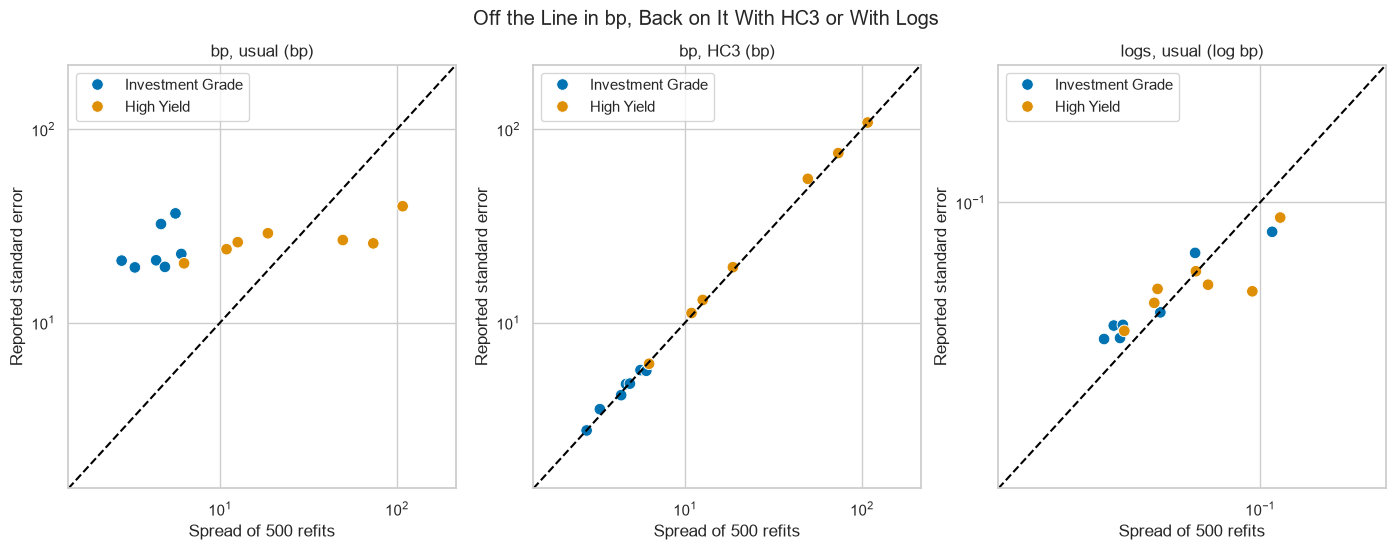

In [37]:
# one dot per rating step: the spread of its 500 refits against the standard error statsmodels reports
fig, axes = plt.subplots(1, 3, figsize=(17, 5.5))
for ax, (name, reported, refits) in zip(axes, panels):
    spread = refits[step_names].std()
    sns.scatterplot(x=spread, y=reported[step_names], hue=step_grade, s=70, ax=ax)
    ax.axline((spread.min(), spread.min()), slope=1, color="black", linestyle="--")
    # both axes on a log scale over the same range, so the 45-degree line runs corner to corner
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlim(spread.min() / 2, spread.max() * 2)
    ax.set_ylim(spread.min() / 2, spread.max() * 2)
    ax.tick_params(which="minor", labelbottom=False, labelleft=False)
    ax.set_title(name)
    ax.set_xlabel("Spread of 500 refits")
    ax.set_ylabel("Reported standard error")
fig.suptitle("Off the Line in bp, Back on It With HC3 or With Logs")
plt.show()

In [38]:
# reported over refitted, one row per rating step: 1 means they agree
pd.DataFrame({name: reported[step_names] / refits[step_names].std() for name, reported, refits in panels})

,"bp, usual (bp)","bp, HC3 (bp)","logs, usual (log bp)"
rating_AAA,6.563,1.015,0.774
rating_AA-,6.982,1.038,1.131
rating_A+,7.537,0.997,1.247
rating_A-,5.851,1.081,1.225
rating_BBB+,4.829,0.969,1.179
rating_BBB,3.753,0.933,0.994
rating_BBB-,3.982,0.991,1.110
rating_BB+,3.239,0.979,1.127
rating_BB,2.205,1.031,1.095
rating_BB-,2.072,1.041,1.166


In [39]:
# AAA's p-value in bp and in logs
print("bp model:", round(bp_model.pvalues["rating_AAA"], 3), " log model:", log_model.pvalues["rating_AAA"])

bp model: 0.176  log model: 3.825851783683608e-36


In bp the usual standard errors are 3.2 to 7.5 times too wide from AAA to BB+, and too narrow from B to CCC+ (0.35 to 0.54).

With HC3 every bp step's ratio sits between 0.93 and 1.12.

In logs the usual standard errors sit on the line, 0.77 to 1.25, apart from B (0.62), which holds three of the distressed bonds found next.

AAA's p-value falls from 0.176 in bp to 3.8e-36 in logs, so the step below A is now clear.

**Two cures: HC3 mends the error bars of a bp model, and logs mend the model itself. We keep the log model.**

# Distressed Bonds and the Final Scores

## The Six Distressed Bonds

### Finding Them

The recipe has one more step: it multiplies six bonds rated B or lower by 2.5 to 4, and the file does not mark them.

Such a bond sits far above its issuer's other bonds, so measure each log spread against its issuer's median (`.transform("median")`).

Q. Which bonds rated B or lower sit furthest above their issuer's other bonds?

In [40]:
# each bond's log spread less its issuer's median log spread; the seven largest gaps among bonds rated B or lower (score 15 up)
gap = log_oas - log_oas.groupby(data["ticker"]).transform("median")
print(gap[data["score"] >= 15].nlargest(7).round(3))

# the six largest, and which of them are training bonds
distressed = gap[data["score"] >= 15].nlargest(6).index
data.loc[distressed, ["cusip", "issuer", "rating", "oas"]].assign(training=distressed.isin(X_train.index))

386   1.737
47    1.186
789   1.148
533   0.922
365   0.701
196   0.555
474   0.434
Name: oas, dtype: float64


,cusip,issuer,rating,oas,training
386,99072UAF5,Zephane Utilities,B,2074,True
47,99009JAA9,Calderby Retail,B,1446,True
789,99145PAB8,Praximer Energy,B-,1718,True
533,99098UAF5,Elvundra Foods,B,933,True
365,99069RAC4,Feskovar Devices,CCC+,1551,True
196,99038MAC3,Praxiskan Finance,CCC+,1605,False


The gaps fall from 1.737 to 0.555, then drop to 0.434 for the seventh bond.

These are the most likely six, not a list the file confirms.

Five are training bonds, and the sixth is Praxiskan Finance, a test bond.

### Where They Sit

Three numbers show how hard each training bond pulls on the fit:

* **Leverage**: how unusual its features are, high for a bond on a rating with few bonds.
* **Studentized residual**: its miss in standard deviations, from a fit without it.
* **Cook's distance**: how far the fitted values move when it is left out, leverage and miss together.

`.get_influence()` gives all three.

In [41]:
# leverage, studentized residual and Cook's distance for every training bond under the log model
# (cooks_distance is a pair, the distances and their p-values, so [0] takes the distances)
influence = log_model.get_influence()
leverage = influence.hat_matrix_diag
studentized = influence.resid_studentized_external
cooks = influence.cooks_distance[0]
is_distressed = X_train.index.isin(distressed)
print("The five, studentized:", np.sort(studentized[is_distressed]).round(1))
print("Largest of the others:", studentized[~is_distressed].max().round(1))

The five, studentized: [2.7 3.3 5.  5.1 6.5]
Largest of the others: 2.7


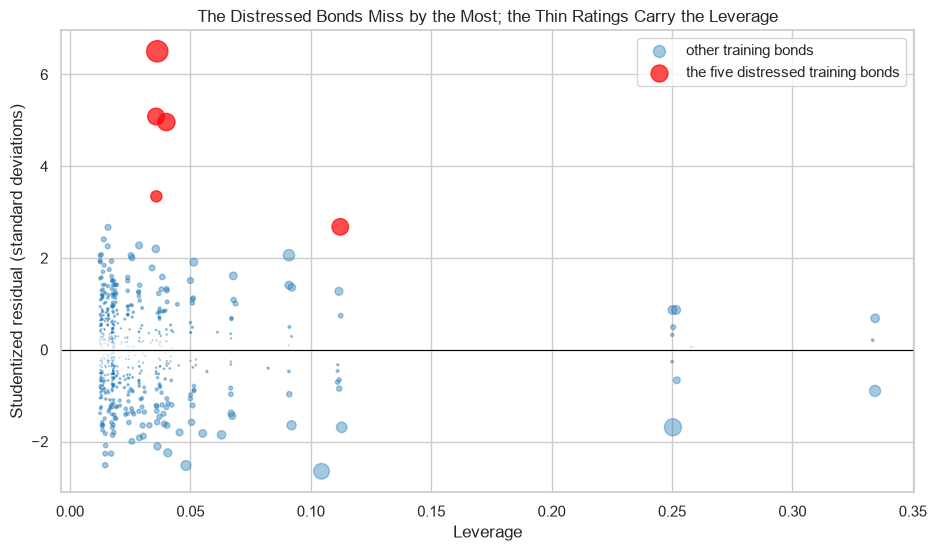

In [42]:
# an influence plot: leverage against studentized residual, each bubble sized by Cook's distance
plt.figure(figsize=(11, 6))
plt.scatter(leverage[~is_distressed], studentized[~is_distressed], s=cooks[~is_distressed] * 3000, alpha=0.4,
            color="tab:blue", label="other training bonds")
plt.scatter(leverage[is_distressed], studentized[is_distressed], s=cooks[is_distressed] * 3000, alpha=0.7,
            color="red", label="the five distressed training bonds")
plt.axhline(0, color="black", linewidth=0.8)
plt.xlabel("Leverage")
plt.ylabel("Studentized residual (standard deviations)")
plt.title("The Distressed Bonds Miss by the Most; the Thin Ratings Carry the Leverage")
plt.legend()
plt.show()

The five's studentized residuals run from 2.7 to 6.5, and no other training bond goes above 2.7.

The bubbles at leverage 0.25 and 0.33 sit on ratings with four and three training bonds, each bond pinning much of its rating's step.

**Five training bonds carry the largest misses the log model leaves.**

### The Checks Without Them

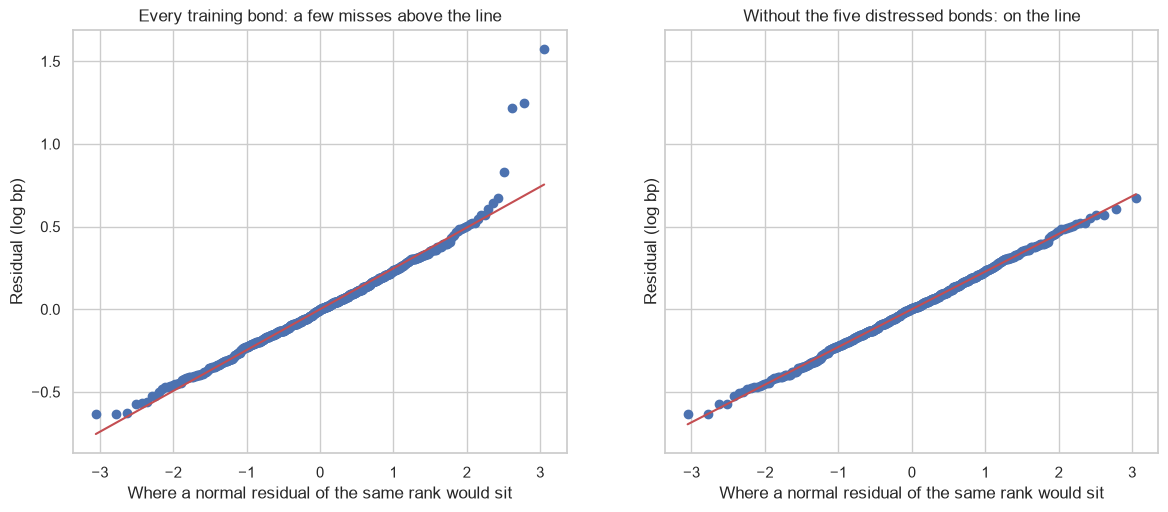

In [43]:
# the log model refitted without the five distressed training bonds
keep = ~is_distressed
log_model_kept = sm.OLS(np.log(y_train[keep]), sm.add_constant(X_train[keep])).fit()

# two Q-Q plots of the log misses: every training bond, and without the five
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), sharey=True)
stats.probplot(log_model.resid, dist="norm", plot=axes[0])
stats.probplot(log_model_kept.resid, dist="norm", plot=axes[1])
axes[0].set_title("Every training bond: a few misses above the line")
axes[1].set_title("Without the five distressed bonds: on the line")
for ax in axes:
    ax.set_xlabel("Where a normal residual of the same rank would sit")
    ax.set_ylabel("Residual (log bp)")
plt.show()

In [44]:
# the three tests without the five, for both targets
bp_model_kept = sm.OLS(y_train[keep], sm.add_constant(X_train[keep])).fit()
for name, model in [("log model", log_model_kept), ("bp model", bp_model_kept)]:
    print(name, " Breusch-Pagan:", het_breuschpagan(model.resid, model.model.exog)[1],
          " Shapiro-Wilk:", stats.shapiro(model.resid).pvalue, " Jarque-Bera:", stats.jarque_bera(model.resid).pvalue)

log model  Breusch-Pagan: 0.3064229676081241  Shapiro-Wilk: 0.8895281280919223  Jarque-Bera: 0.644587458566996
bp model  Breusch-Pagan: 5.516621838049834e-28  Shapiro-Wilk: 2.763563387267495e-22  Jarque-Bera: 0.0


Without the five, the log model passes all three tests, with p-values of 0.31, 0.89 and 0.64.

The bp model still fails all three, so its fan was never about these bonds.

### Keep or Drop

In [45]:
# the test MAE in bp of the log model fitted without the five
print("Test MAE without the five:", round(mean_absolute_error(y_test, np.exp(log_model_kept.predict(sm.add_constant(X_test)))), 2))

Test MAE without the five: 33.59


Without them the test MAE moves from 33.11 to 33.59 bp, no better on unseen bonds.

**They are real bonds, not errors, so we keep them, and say that five of them are why the tests reject in logs.**

## Model Performance Comparison

### Training and Test MAE

Q. Does either model miss unseen bonds by more than the bonds it was fitted on?

In [46]:
# training and test MAE in bp for both models
pd.DataFrame({"bp model": [mean_absolute_error(y_train, bp_model.fittedvalues), test_scores.loc["bp model", "MAE (bp)"]],
              "log model": [mean_absolute_error(y_train, np.exp(log_model.fittedvalues)), test_scores.loc["log model", "MAE (bp)"]]},
             index=["training MAE (bp)", "test MAE (bp)"])

,bp model,log model
training MAE (bp),42.770,40.087
test MAE (bp),35.445,33.109


The log model misses less on both sides, 40.1 against 42.8 bp in training and 33.1 against 35.4 on test.

Test errors are no worse than training errors, so neither model is overfitting.

# Insights and Conclusion

In bp, Day 3's model has the right shape, but its noise grows with the spread and its misses are far from normal.

The recipe multiplies, so the noise is a percent, and the log makes it one size: top over bottom falls from 11.8 to 1.32.

Without the five distressed training bonds, every test passes in logs.

A rating step reads as a percent from A and tracks the recipe, and the log model's error bars agree with the refits.

On unseen bonds the typical miss falls from 35.4 to 33.1 bp.

**Day 5 starts from the log target and these columns.**

# Wrapping Up

## You Can Now

By the end of this notebook, you can:

* Check linearity, constant variance, normality and independence, each with a chart and a number.
* Read a lowess line, a scale-location plot and a Q-Q plot.
* Fit a model on log OAS, bring it back to bp with `np.exp`, and say why `exp` gives the middle bond.
* Read a log coefficient as a percent.
* Mend error bars with HC3 or with logs, and find the bonds that pull hardest on a fit.

## Exercises

Run this cell first: `check()` marks each answer as correct, not yet, or not attempted.

In [47]:
# check() compares your answer with the expected one
def check(label, answer, expected):
    if answer is ...:
        print(label + ": not attempted yet")
    elif isinstance(expected, float) and abs(answer - expected) < 1e-6:
        print(label + ": correct")
    elif answer == expected:
        print(label + ": correct")
    else:
        print(label + ": not yet. You have", answer)

### Exercise 1

**Investment Grade Only**

Q. Fit the log model on the investment grade bonds alone: their rating steps from A and years to maturity, split with `test_size=0.25` and `random_state=SEED`.
Store its Breusch-Pagan p-value in `ex1_bp_p_value`, and its top-over-bottom ratio from `std_by_third` in `ex1_top_over_bottom`.

In [48]:
# the investment grade bonds, and their rating steps from A plus years to maturity
ig = data["grade"] == "Investment Grade"
ig_levels = ratings.loc[ratings["grade"] == "Investment Grade", "rating"]
ig_columns = ["rating_" + level for level in ig_levels if level != "A"] + ["years_to_maturity"]
ig_X_train, ig_X_test, ig_y_train, ig_y_test = train_test_split(X.loc[ig, ig_columns], y[ig], test_size=0.25,
                                                                random_state=SEED)

In [49]:
# the log model on the investment grade training bonds, then its two checks
ig_model = sm.OLS(np.log(ig_y_train), sm.add_constant(ig_X_train)).fit()
ex1_bp_p_value = het_breuschpagan(ig_model.resid, ig_model.model.exog)[1]
ig_thirds = std_by_third(ig_model.fittedvalues, ig_model.resid)
ex1_top_over_bottom = ig_thirds["top"] / ig_thirds["bottom"]
print(len(ig_X_train), len(ig_X_test), round(ex1_bp_p_value, 3), round(ex1_top_over_bottom, 2))

405 135 0.313 1.04


In [50]:
# Jarque-Bera in logs, and the same thirds in bp, for comparison
ig_bp_model = sm.OLS(ig_y_train, sm.add_constant(ig_X_train)).fit()
ig_bp_thirds = std_by_third(ig_bp_model.fittedvalues, ig_bp_model.resid)
print("Jarque-Bera p-value in logs:", round(stats.jarque_bera(ig_model.resid).pvalue, 3))
print("Top over bottom in bp:", round(ig_bp_thirds["top"] / ig_bp_thirds["bottom"], 2))

Jarque-Bera p-value in logs: 0.639
Top over bottom in bp: 2.39


405 training and 135 test bonds, none of them distressed.

In logs both checks pass: Breusch-Pagan p 0.313, Jarque-Bera p 0.639, top over bottom 1.04.

The same bonds in bp give 2.39: even inside investment grade the noise is a percent.

In [51]:
check("Exercise 1 the Breusch-Pagan p-value", ex1_bp_p_value, 0.31319328200873253)
check("Exercise 1 top over bottom", ex1_top_over_bottom, 1.0385638140969276)

Exercise 1 the Breusch-Pagan p-value: correct
Exercise 1 top over bottom: correct


### Exercise 2

**Years Capped at 10**

Q. The recipe caps years to maturity at 10 (Day 3).
Refit the log model on the same training bonds with `years_to_maturity` capped by `.clip(upper=10)`, in training and test alike.
Store the years coefficient as a percent per year in `ex2_percent_per_year`, and the test MAE in bp in `ex2_test_mae_bp`.

In [52]:
# years to maturity capped at 10, for the same training and test bonds
capped_train = X_train.assign(years_to_maturity=X_train["years_to_maturity"].clip(upper=10))
capped_test = X_test.assign(years_to_maturity=X_test["years_to_maturity"].clip(upper=10))

# the log model on the capped column, its years coefficient as a percent, and its test MAE in bp
capped_model = sm.OLS(np.log(y_train), sm.add_constant(capped_train)).fit()
ex2_percent_per_year = 100 * (np.exp(capped_model.params["years_to_maturity"]) - 1)
ex2_test_mae_bp = mean_absolute_error(y_test, np.exp(capped_model.predict(sm.add_constant(capped_test))))
print(round(ex2_percent_per_year, 2), round(ex2_test_mae_bp, 2))

2.87 32.97


2.87 percent per year once capped, against 0.97 uncapped, and a test MAE of 32.97 bp against 33.11.

Past 10 years the recipe adds nothing, so an uncapped column spreads the same effect thin over 30 years.

In [53]:
check("Exercise 2 the percent per year", ex2_percent_per_year, 2.871821245293771)
check("Exercise 2 the test MAE", ex2_test_mae_bp, 32.97110160505322)

Exercise 2 the percent per year: correct
Exercise 2 the test MAE: correct


### Exercise 3

**A Step as a Percent**

Q. Write `percent_effect(coef)`: it returns 100 x (exp(coef) - 1).
Use it on the log model's CCC+ coefficient and store the result in `ex3_ccc_percent`.

In [54]:
# a log coefficient as a percent difference
def percent_effect(coef):
    return 100 * (np.exp(coef) - 1)

ex3_ccc_percent = percent_effect(log_model.params["rating_CCC+"])
print(round(ex3_ccc_percent, 1), round(percent_effect(log_model.params["rating_BB"]), 1))

1084.5 210.1


CCC+ sits 1,084.5 percent above A, a multiplier of 11.85, and BB 210.1 percent, as the percent table showed.

A large coefficient in logs is a very large percent, so quote the multiplier beside it.

In [55]:
check("Exercise 3 the CCC+ step as a percent", ex3_ccc_percent, 1084.5142548211677)

Exercise 3 the CCC+ step as a percent: correct


### Exercise 4: AI check

**The Log Model's Test MAE**

You asked an AI assistant for the log model's test MAE in bp.

This came back.

It runs, and the number looks like a spread.

In [56]:
# written for this course in the style of an AI assistant's answer: it runs, and it has one bug
def log_model_test_mae_bp(model):
    # the log model's fitted values for the test bonds, scored against their spreads
    fitted = model.predict(sm.add_constant(X_test))
    return mean_absolute_error(y_test, fitted)

print("Log model test MAE in bp:", round(log_model_test_mae_bp(log_model), 1))

Log model test MAE in bp: 169.4


Q. What unit is 169.4 in?
Fix the function and store its test MAE in bp in `ex4_test_mae_bp`.

In [57]:
# the fix: exp turns the fitted logs back into bp before scoring
def log_model_test_mae_bp(model):
    fitted = np.exp(model.predict(sm.add_constant(X_test)))
    return mean_absolute_error(y_test, fitted)

ex4_test_mae_bp = log_model_test_mae_bp(log_model)
print(round(ex4_test_mae_bp, 2))

33.11


169.4 is spreads in bp less fitted logs, a number with no unit: about 174 bp of spread less about 5 of log.

With `np.exp` the fitted logs come back to bp, and the MAE is 33.11 bp, the log model's test MAE.

A number in the right range is not a check, and the unit is.

In [58]:
check("Exercise 4 the fixed test MAE", ex4_test_mae_bp, 33.10876778506247)

Exercise 4 the fixed test MAE: correct


## Congratulations!

You tested every assumption under a regression today, with a chart and a number each.
You found the fan, traced it to a recipe that multiplies, and closed it by fitting the log of the spread.
You brought the log model back to bp, saw why `exp` gives the middle bond, and read a rating step as a percent.
You mended error bars two ways and found the distressed bonds behind the last failed tests.
On Day 5 you put all of it to work on a case study.

[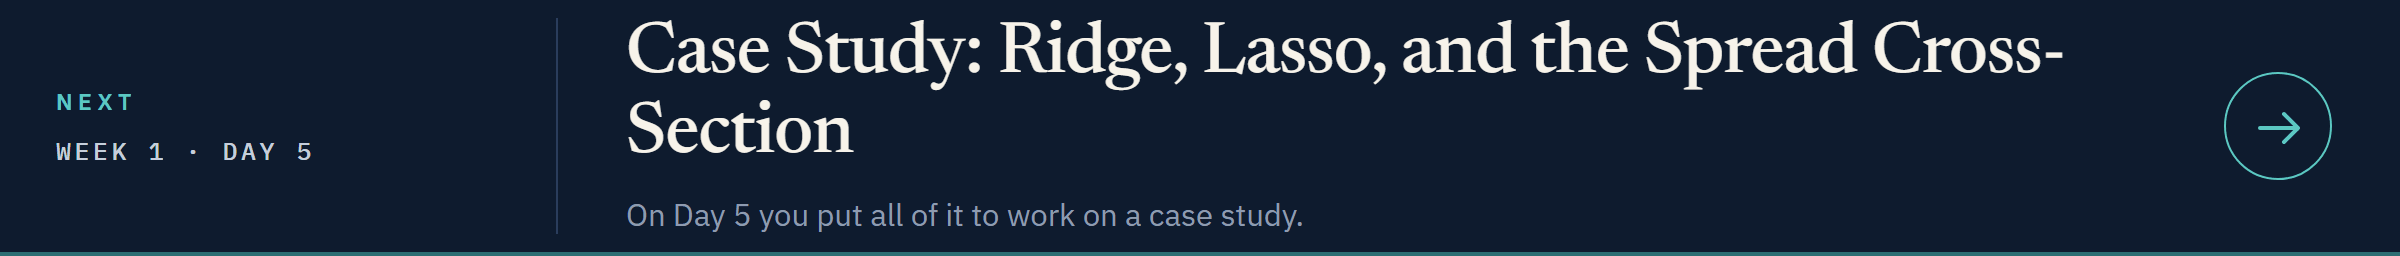](../day5/05_case_study_ridge_lasso_and_the_spread_cross_section.ipynb)

[Open Day 5 in Colab](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course04_machine_learning/week1/day5/05_case_study_ridge_lasso_and_the_spread_cross_section.ipynb)